# Importing The Required Libraries


In [66]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn import preprocessing
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor, VotingClassifier,VotingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score,mean_squared_error
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import sklearn.metrics as metrics
import seaborn as sns

# Importing the Weather Dataset

In [67]:
df = pd.read_csv(r'C:\Users\Tanvir Ann Noor\Downloads\Weather_Data.csv')

df.head()

,Date,Temp9am,Temp3pm,MinTemp,MaxTemp,Rainfall,RainToday,Evaporation,Sunshine,WindGustDir,...,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm
0,01-02-13,20.7,20.9,19.5,22.4,15.6,Yes,6.2,0.0,W,...,S,SSW,17,20,92,84,1017.6,1017.4,8,8
1,02-02-13,22.4,24.8,19.5,25.6,6.0,Yes,3.4,2.7,W,...,W,E,9,13,83,73,1017.9,1016.4,7,7
2,03-02-13,23.5,23.0,21.6,24.5,6.6,Yes,2.4,0.1,W,...,ESE,ESE,17,2,88,86,1016.7,1015.6,7,8
3,04-02-13,21.4,20.9,20.2,22.8,18.8,Yes,2.2,0.0,W,...,NNE,E,22,20,83,90,1014.2,1011.8,8,8
4,05-02-13,22.5,25.5,19.7,25.7,77.4,Yes,4.8,0.0,W,...,NNE,W,11,6,88,74,1008.3,1004.8,8,8


In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3271 entries, 0 to 3270
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           3271 non-null   object 
 1   Temp9am        3271 non-null   float64
 2   Temp3pm        3271 non-null   float64
 3   MinTemp        3271 non-null   float64
 4   MaxTemp        3271 non-null   float64
 5   Rainfall       3271 non-null   float64
 6   RainToday      3271 non-null   object 
 7   Evaporation    3271 non-null   float64
 8   Sunshine       3271 non-null   float64
 9   WindGustDir    3271 non-null   object 
 10  WindGustSpeed  3271 non-null   int64  
 11  WindDir9am     3271 non-null   object 
 12  WindDir3pm     3271 non-null   object 
 13  WindSpeed9am   3271 non-null   int64  
 14  WindSpeed3pm   3271 non-null   int64  
 15  Humidity9am    3271 non-null   int64  
 16  Humidity3pm    3271 non-null   int64  
 17  Pressure9am    3271 non-null   float64
 18  Pressure

In [69]:
df.describe()

,Temp9am,Temp3pm,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm
count,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000
mean,17.821461,21.543656,14.877102,23.005564,3.342158,5.175787,7.168970,41.476307,15.077041,19.294405,68.243962,54.698563,1018.334424,1016.003085,4.318557,4.176093
std,4.894316,4.297053,4.554710,4.483752,9.917746,2.757684,3.815966,10.806951,7.043825,7.453331,15.086127,16.279241,7.020090,7.019915,2.526923,2.411274
min,6.400000,10.200000,4.300000,11.700000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,19.000000,10.000000,986.700000,989.800000,0.000000,0.000000
25%,13.800000,18.400000,11.000000,19.600000,0.000000,3.200000,4.250000,35.000000,11.000000,15.000000,58.000000,44.000000,1013.700000,1011.300000,2.000000,2.000000
50%,18.200000,21.300000,14.900000,22.800000,0.000000,4.800000,8.300000,41.000000,15.000000,19.000000,69.000000,56.000000,1018.600000,1016.300000,5.000000,4.000000
75%,21.700000,24.500000,18.800000,26.000000,1.400000,7.000000,10.200000,44.000000,20.000000,24.000000,80.000000,64.000000,1023.100000,1020.800000,7.000000,7.000000
max,36.500000,44.700000,27.600000,45.800000,119.400000,18.400000,13.600000,96.000000,54.000000,57.000000,100.000000,99.000000,1039.000000,1036.700000,9.000000,8.000000


# Features Distribution

#### Minimum Temperature Distribution

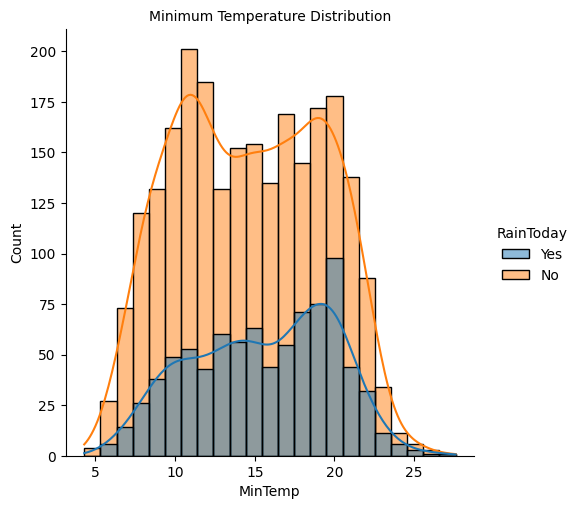

In [70]:
sns.displot(df, x="MinTemp", hue='RainToday', kde=True)
plt.title("Minimum Temperature Distribution", fontsize = 10)
plt.show()

#### Maximum Temperature Distribution

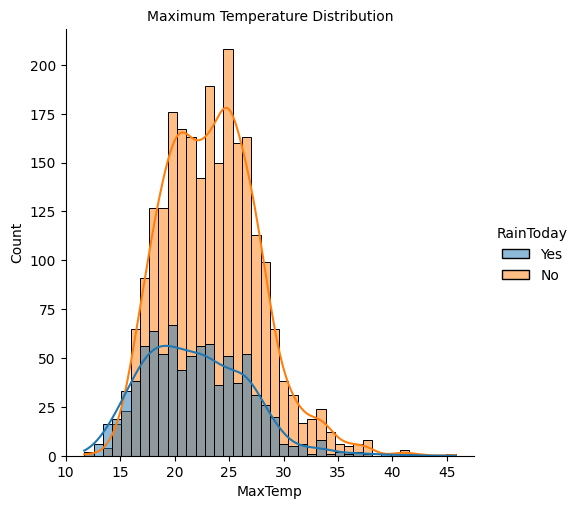

In [71]:
sns.displot(df, x="MaxTemp", hue='RainToday', kde=True)
plt.title("Maximum Temperature Distribution", fontsize = 10)
plt.show()


#### Wind Gust Distribution

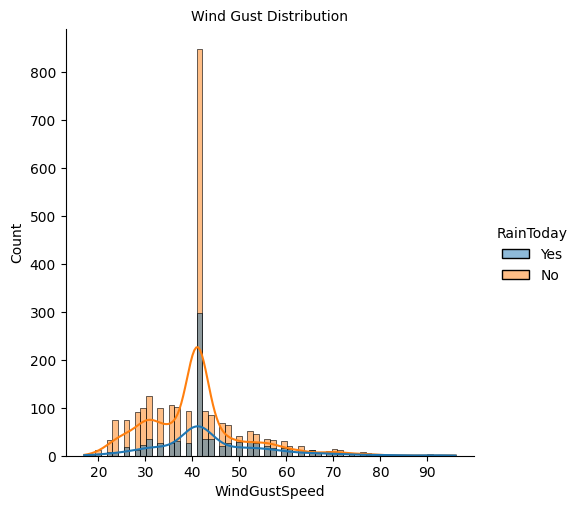

In [72]:
sns.displot(df, x="WindGustSpeed", hue='RainToday', kde=True)
plt.title("Wind Gust Distribution", fontsize = 10)
plt.show()

#### Wind Speed at 9am Distribution

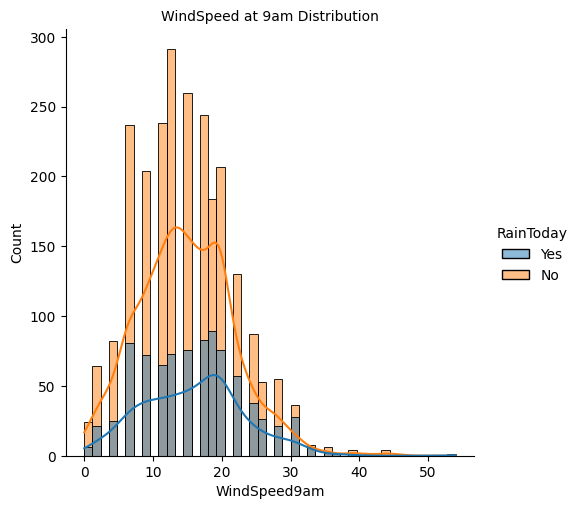

In [73]:
sns.displot(df, x="WindSpeed9am", hue='RainToday', kde=True)
plt.title("WindSpeed at 9am Distribution", fontsize = 10)
plt.show()

#### Wind Speed at 3am Distribution

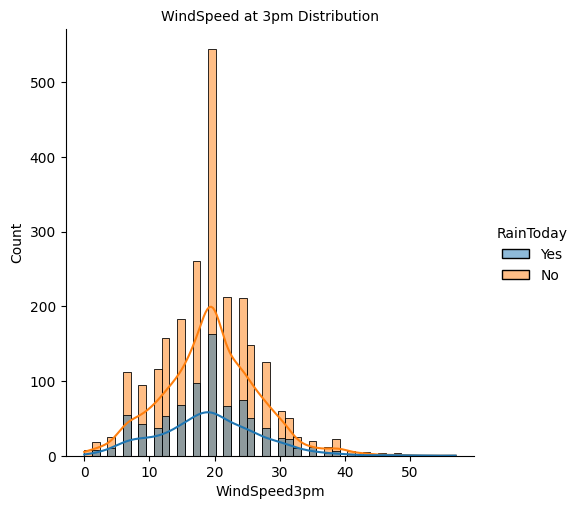

In [74]:
sns.displot(df, x="WindSpeed3pm", hue='RainToday', kde=True)
plt.title("WindSpeed at 3pm Distribution", fontsize = 10)
plt.show()

#### Humidity at 9am Distributon

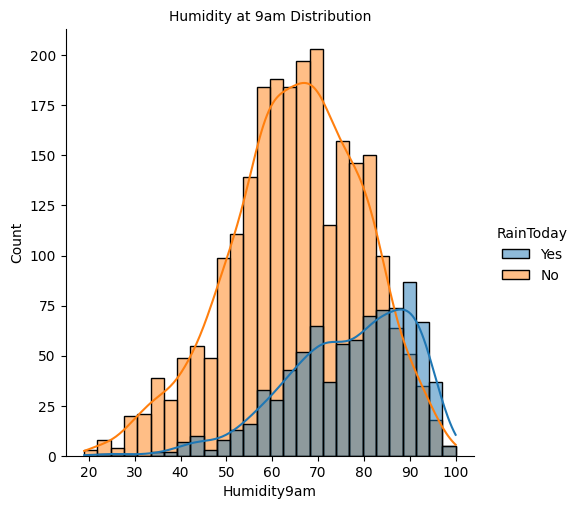

In [75]:
sns.displot(df, x="Humidity9am", hue='RainToday', kde=True)
plt.title("Humidity at 9am Distribution", fontsize = 10)
plt.show()

#### Humidity at 3pm Distributon

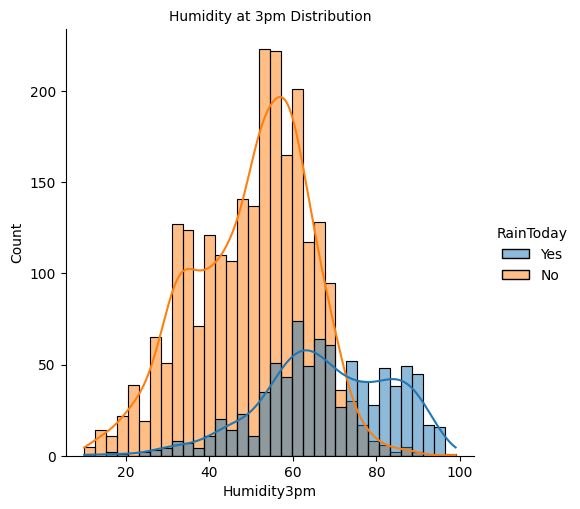

In [76]:
sns.displot(df, x="Humidity3pm", hue='RainToday', kde=True)
plt.title("Humidity at 3pm Distribution", fontsize = 10)
plt.show()

#### Pressure at 9am Distributon

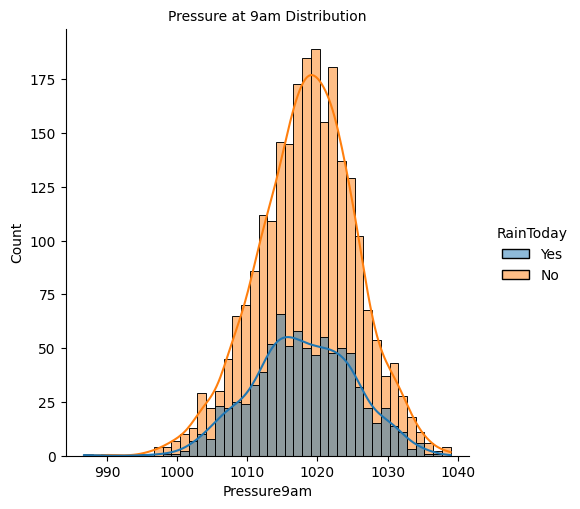

In [77]:
sns.displot(df, x="Pressure9am", hue='RainToday', kde=True)
plt.title("Pressure at 9am Distribution", fontsize = 10)
plt.show()

#### Pressure at 3pm Distributon

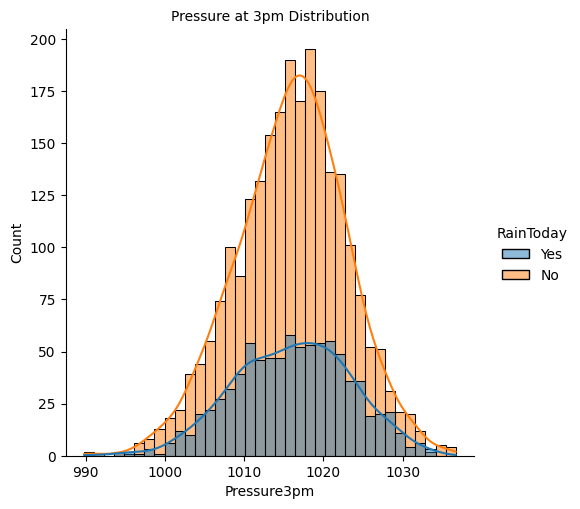

In [78]:
sns.displot(df, x="Pressure3pm", hue='RainToday', kde=True)
plt.title("Pressure at 3pm Distribution", fontsize = 10)
plt.show()

#### Cloud at 9am Distribution

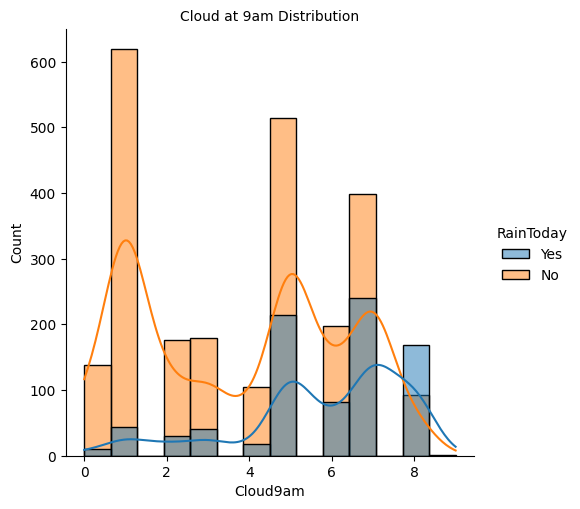

In [79]:
sns.displot(df, x="Cloud9am", hue='RainToday', kde=True)
plt.title("Cloud at 9am Distribution", fontsize = 10)
plt.show()

#### Cloud at 3pm Distribution

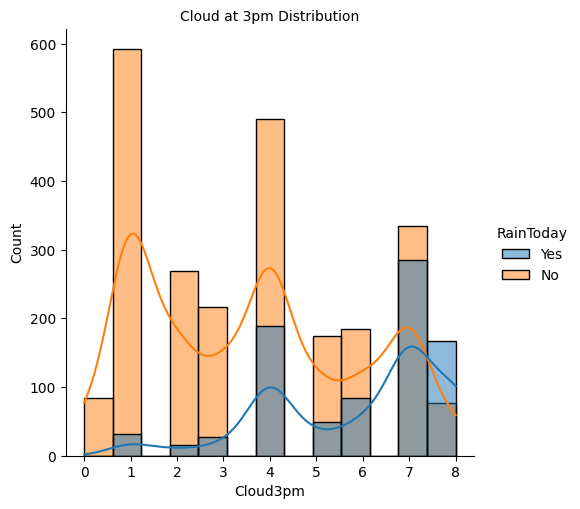

In [80]:
sns.displot(df, x="Cloud3pm", hue='RainToday', kde=True)
plt.title("Cloud at 3pm Distribution", fontsize = 10)
plt.show()

#### Temperature at 9am Distribution

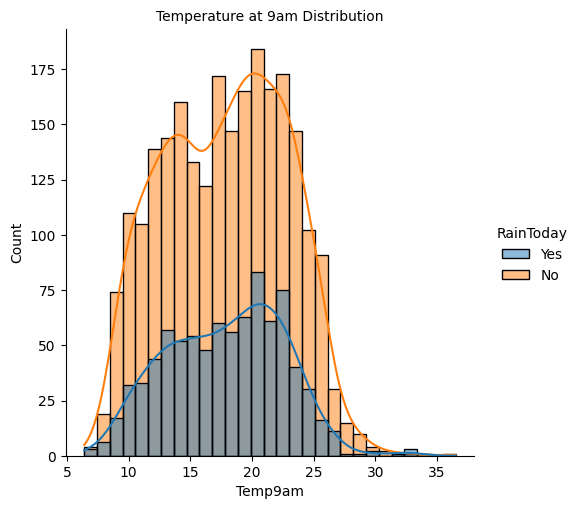

In [81]:
sns.displot(df, x="Temp9am", hue='RainToday', kde=True)
plt.title("Temperature at 9am Distribution", fontsize = 10)
plt.show()

#### Temperature at 3pm Distribution

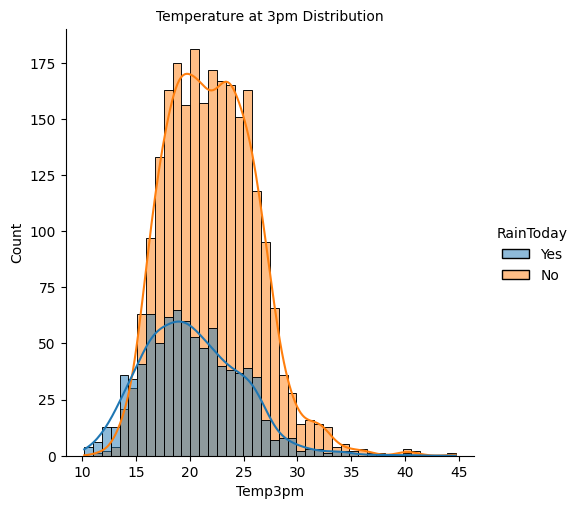

In [82]:
sns.displot(df, x="Temp3pm", hue='RainToday', kde=True)
plt.title("Temperature at 3pm Distribution", fontsize = 10)
plt.show()

# Average Wind Speed Analysis

In [83]:
windspeed_weather_df = df.groupby(df['Date'].str[3:5])[['WindSpeed9am', 'WindSpeed3pm']].mean()
windspeed_weather_df = windspeed_weather_df.reset_index()
windspeed_weather_df

,Date,WindSpeed9am,WindSpeed3pm
0,01,15.285171,17.403042
1,02,15.468504,18.228346
2,03,15.989247,18.053763
3,04,16.466667,19.396296
4,05,16.580645,18.419355
5,06,15.077778,18.807407
6,07,14.612903,20.229391
7,08,13.645161,20.114695
8,09,13.818519,21.203704
9,10,13.896057,21.007168


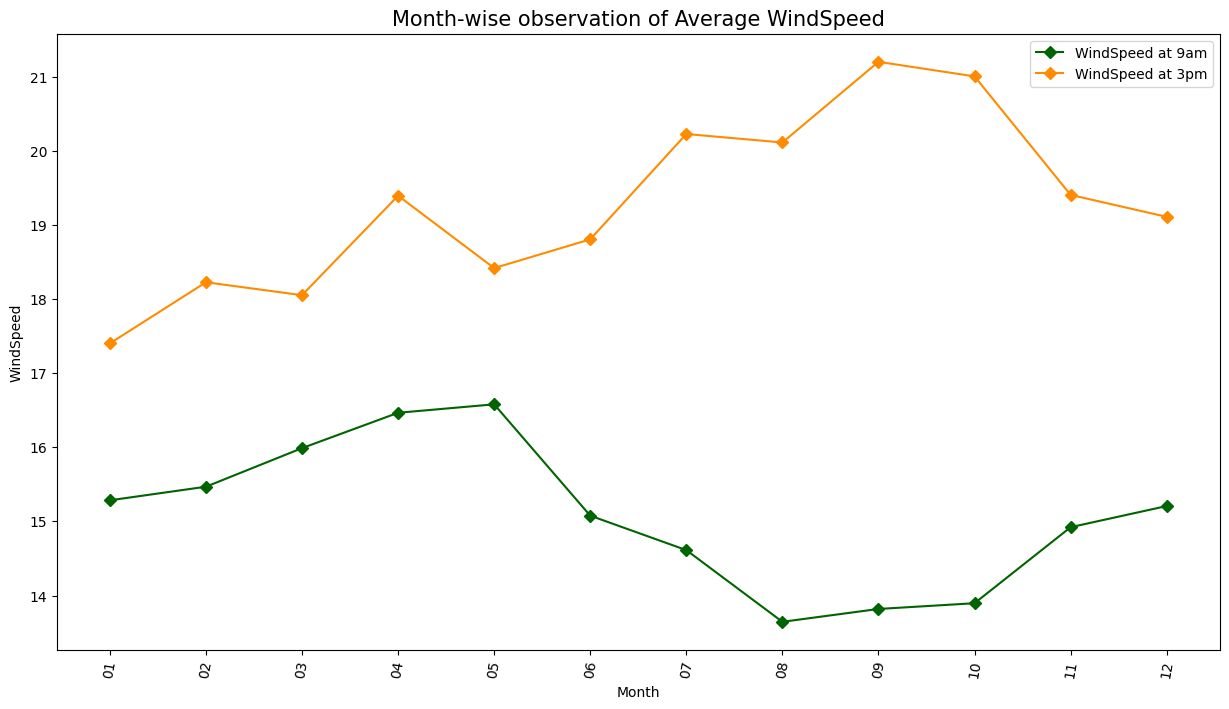

In [84]:
x = windspeed_weather_df.loc[:, 'Date']
y1 = windspeed_weather_df['WindSpeed9am'] 
y2 = windspeed_weather_df['WindSpeed3pm']

plt.figure(figsize = (15, 8))

plt.plot(x, y1, marker='D', color = 'darkgreen', label = 'WindSpeed at 9am') 
plt.plot(x, y2, marker='D', color = 'darkorange', label = 'WindSpeed at 3pm')

plt.xlabel('Month', fontsize = 10)
plt.ylabel('WindSpeed', fontsize = 10)
plt.title('Month-wise observation of Average WindSpeed', fontsize = 15)
plt.legend(fontsize = 10, loc = 'best')
plt.xticks(rotation=80)
plt.show()

# Average Humidity Analysis

In [85]:
humidity_weather_df = df.groupby(df['Date'].str[3:5])[['Humidity9am', 'Humidity3pm']].mean()
humidity_weather_df = humidity_weather_df.reset_index()
humidity_weather_df

,Date,Humidity9am,Humidity3pm
0,01,73.574144,57.136882
1,02,72.830709,56.468504
2,03,68.519713,52.698925
3,04,67.285185,52.374074
4,05,64.014337,49.906810
5,06,66.433333,54.000000
6,07,65.179211,52.333333
7,08,64.164875,52.867384
8,09,65.844444,56.100000
9,10,71.197133,59.139785


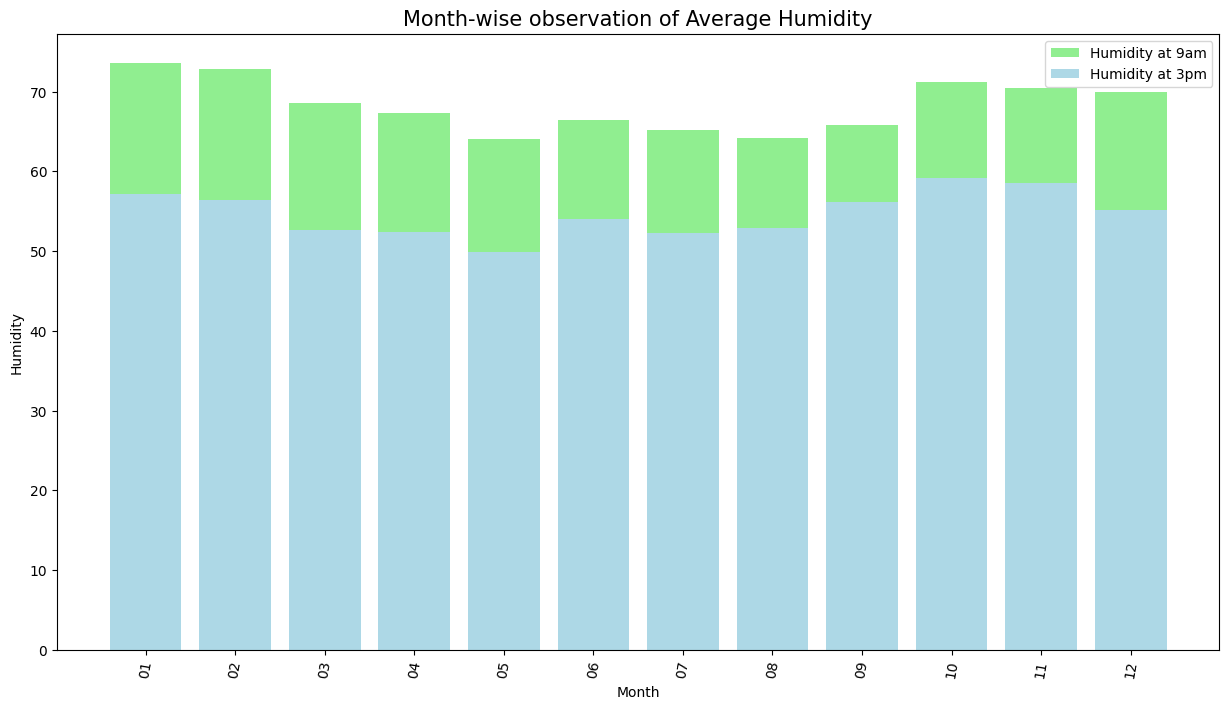

In [86]:
x = humidity_weather_df.loc[:, 'Date']
y1 = humidity_weather_df['Humidity9am'] 
y2 = humidity_weather_df['Humidity3pm']

plt.figure(figsize = (15, 8))

plt.bar(x, y1, color = 'lightgreen', label = 'Humidity at 9am') 
plt.bar(x, y2, color = 'lightblue',label = 'Humidity at 3pm')

plt.xlabel('Month', fontsize = 10)
plt.ylabel('Humidity', fontsize = 10)
plt.title('Month-wise observation of Average Humidity', fontsize = 15)
plt.legend(fontsize = 10, loc = 'best')
plt.xticks(rotation=80)
plt.show()

# Average Pressure Analysis

In [87]:
pressure_weather_df = df.groupby(df['Date'].str[3:5])[['Pressure9am', 'Pressure3pm']].mean()
pressure_weather_df = pressure_weather_df.reset_index()
pressure_weather_df

,Date,Pressure9am,Pressure3pm
0,01,1019.358175,1017.123574
1,02,1018.531496,1016.374803
2,03,1020.687097,1018.254122
3,04,1020.229630,1017.622222
4,05,1019.886738,1017.269391
5,06,1018.396667,1015.952593
6,07,1017.147670,1014.789964
7,08,1015.941577,1013.565789
8,09,1016.675556,1014.475100
9,10,1018.082079,1016.032258


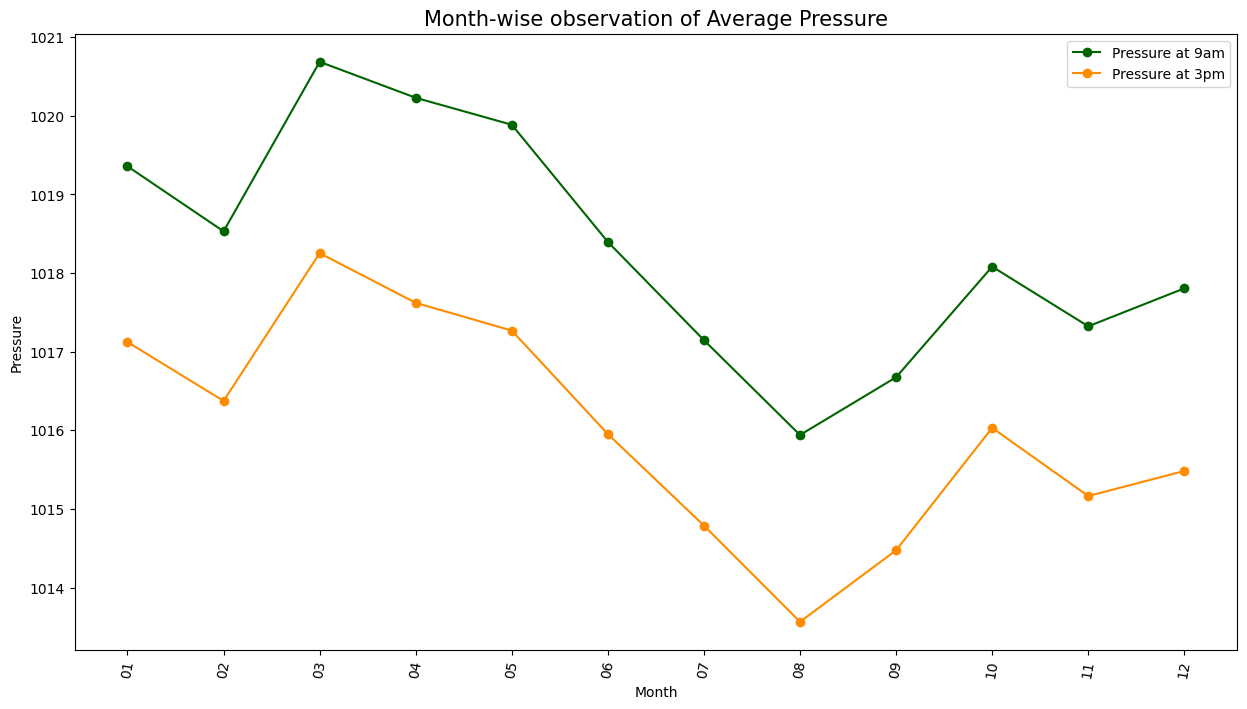

In [88]:
x = pressure_weather_df.loc[:, 'Date']
y1 = pressure_weather_df['Pressure9am'] 
y2 = pressure_weather_df['Pressure3pm']

plt.figure(figsize = (15, 8))

plt.plot(x, y1, marker='o', color = 'darkgreen', label = 'Pressure at 9am') 
plt.plot(x, y2, marker='o', color = 'darkorange', label = 'Pressure at 3pm')

plt.xlabel('Month', fontsize = 10)
plt.ylabel('Pressure', fontsize = 10)
plt.title('Month-wise observation of Average Pressure', fontsize = 15)
plt.legend(fontsize = 10, loc = 'best')
plt.xticks(rotation=80)
plt.show()

# Average Temperrature Analysis

In [89]:
location_weather_df = df.groupby(df['Date'].str[3:5])[['MinTemp', 'MaxTemp', 'Temp9am', 'Temp3pm']].mean()
location_weather_df = location_weather_df.reset_index()
location_weather_df

,Date,MinTemp,MaxTemp,Temp9am,Temp3pm
0,01,14.851331,22.621673,17.158555,21.422814
1,02,14.154331,21.984252,16.439764,20.783858
2,03,12.713620,21.339068,15.451971,20.127599
3,04,12.600000,21.145926,15.721111,19.736667
4,05,12.651971,21.878495,15.939785,20.335125
5,06,13.621852,22.000741,16.786296,20.429259
6,07,14.223297,22.521505,17.465591,20.882437
7,08,15.870251,24.025090,19.237276,22.390323
8,09,17.608148,25.315926,21.029630,23.648889
9,10,17.709319,24.853047,20.483154,23.400000


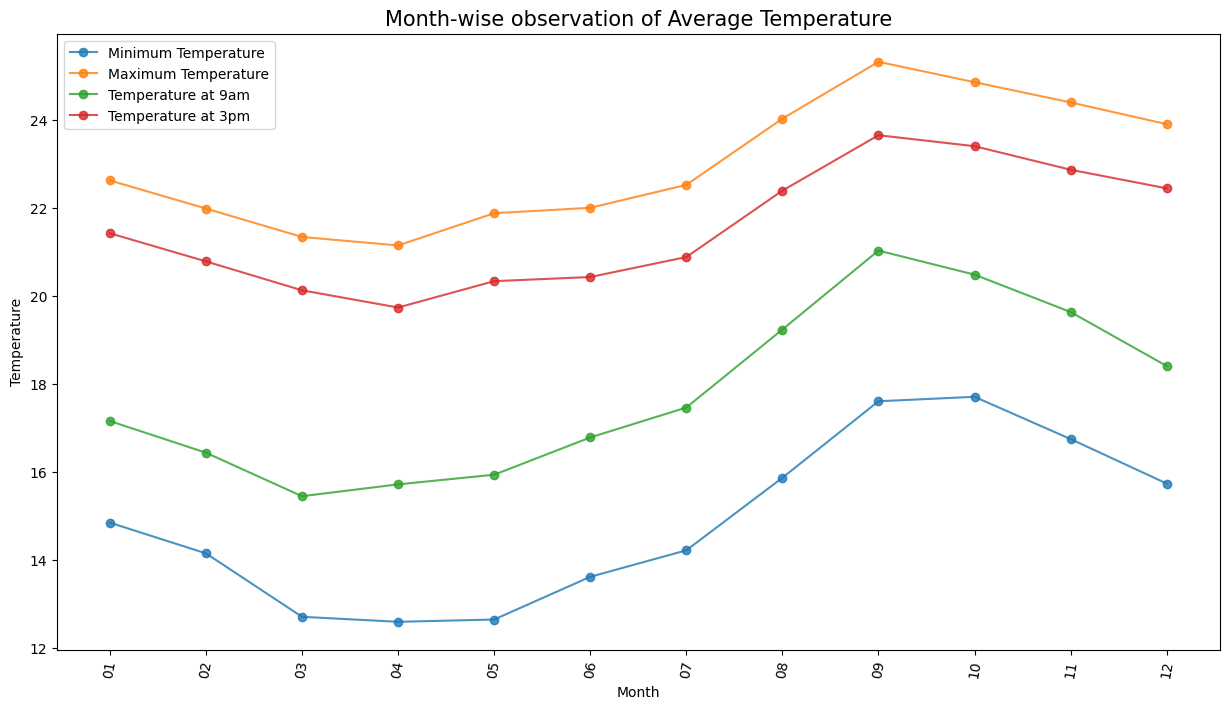

In [90]:
x = location_weather_df.loc[:, 'Date']
y1 = location_weather_df['MinTemp'] 
y2 = location_weather_df['MaxTemp']
y3 = location_weather_df['Temp9am'] 
y4 = location_weather_df['Temp3pm']

plt.figure(figsize = (15, 8))

plt.plot(x, y1, label = 'Minimum Temperature', marker='o', alpha = 0.8) 
plt.plot(x, y2, label = 'Maximum Temperature', marker='o', alpha = 0.8) 
plt.plot(x, y3, label = 'Temperature at 9am', marker='o', alpha = 0.8) 
plt.plot(x, y4, label = 'Temperature at 3pm', marker='o', alpha = 0.8)

plt.xlabel('Month', fontsize = 10)
plt.ylabel('Temperature', fontsize = 10)
plt.title('Month-wise observation of Average Temperature', fontsize = 15)
plt.legend(fontsize = 10, loc = 'best')
plt.xticks(rotation=80)
plt.show()

# Correlation and Description of the data

In [91]:
df.describe()

,Temp9am,Temp3pm,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm
count,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000
mean,17.821461,21.543656,14.877102,23.005564,3.342158,5.175787,7.168970,41.476307,15.077041,19.294405,68.243962,54.698563,1018.334424,1016.003085,4.318557,4.176093
std,4.894316,4.297053,4.554710,4.483752,9.917746,2.757684,3.815966,10.806951,7.043825,7.453331,15.086127,16.279241,7.020090,7.019915,2.526923,2.411274
min,6.400000,10.200000,4.300000,11.700000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,19.000000,10.000000,986.700000,989.800000,0.000000,0.000000
25%,13.800000,18.400000,11.000000,19.600000,0.000000,3.200000,4.250000,35.000000,11.000000,15.000000,58.000000,44.000000,1013.700000,1011.300000,2.000000,2.000000
50%,18.200000,21.300000,14.900000,22.800000,0.000000,4.800000,8.300000,41.000000,15.000000,19.000000,69.000000,56.000000,1018.600000,1016.300000,5.000000,4.000000
75%,21.700000,24.500000,18.800000,26.000000,1.400000,7.000000,10.200000,44.000000,20.000000,24.000000,80.000000,64.000000,1023.100000,1020.800000,7.000000,7.000000
max,36.500000,44.700000,27.600000,45.800000,119.400000,18.400000,13.600000,96.000000,54.000000,57.000000,100.000000,99.000000,1039.000000,1036.700000,9.000000,8.000000


FInding the Correlation Values

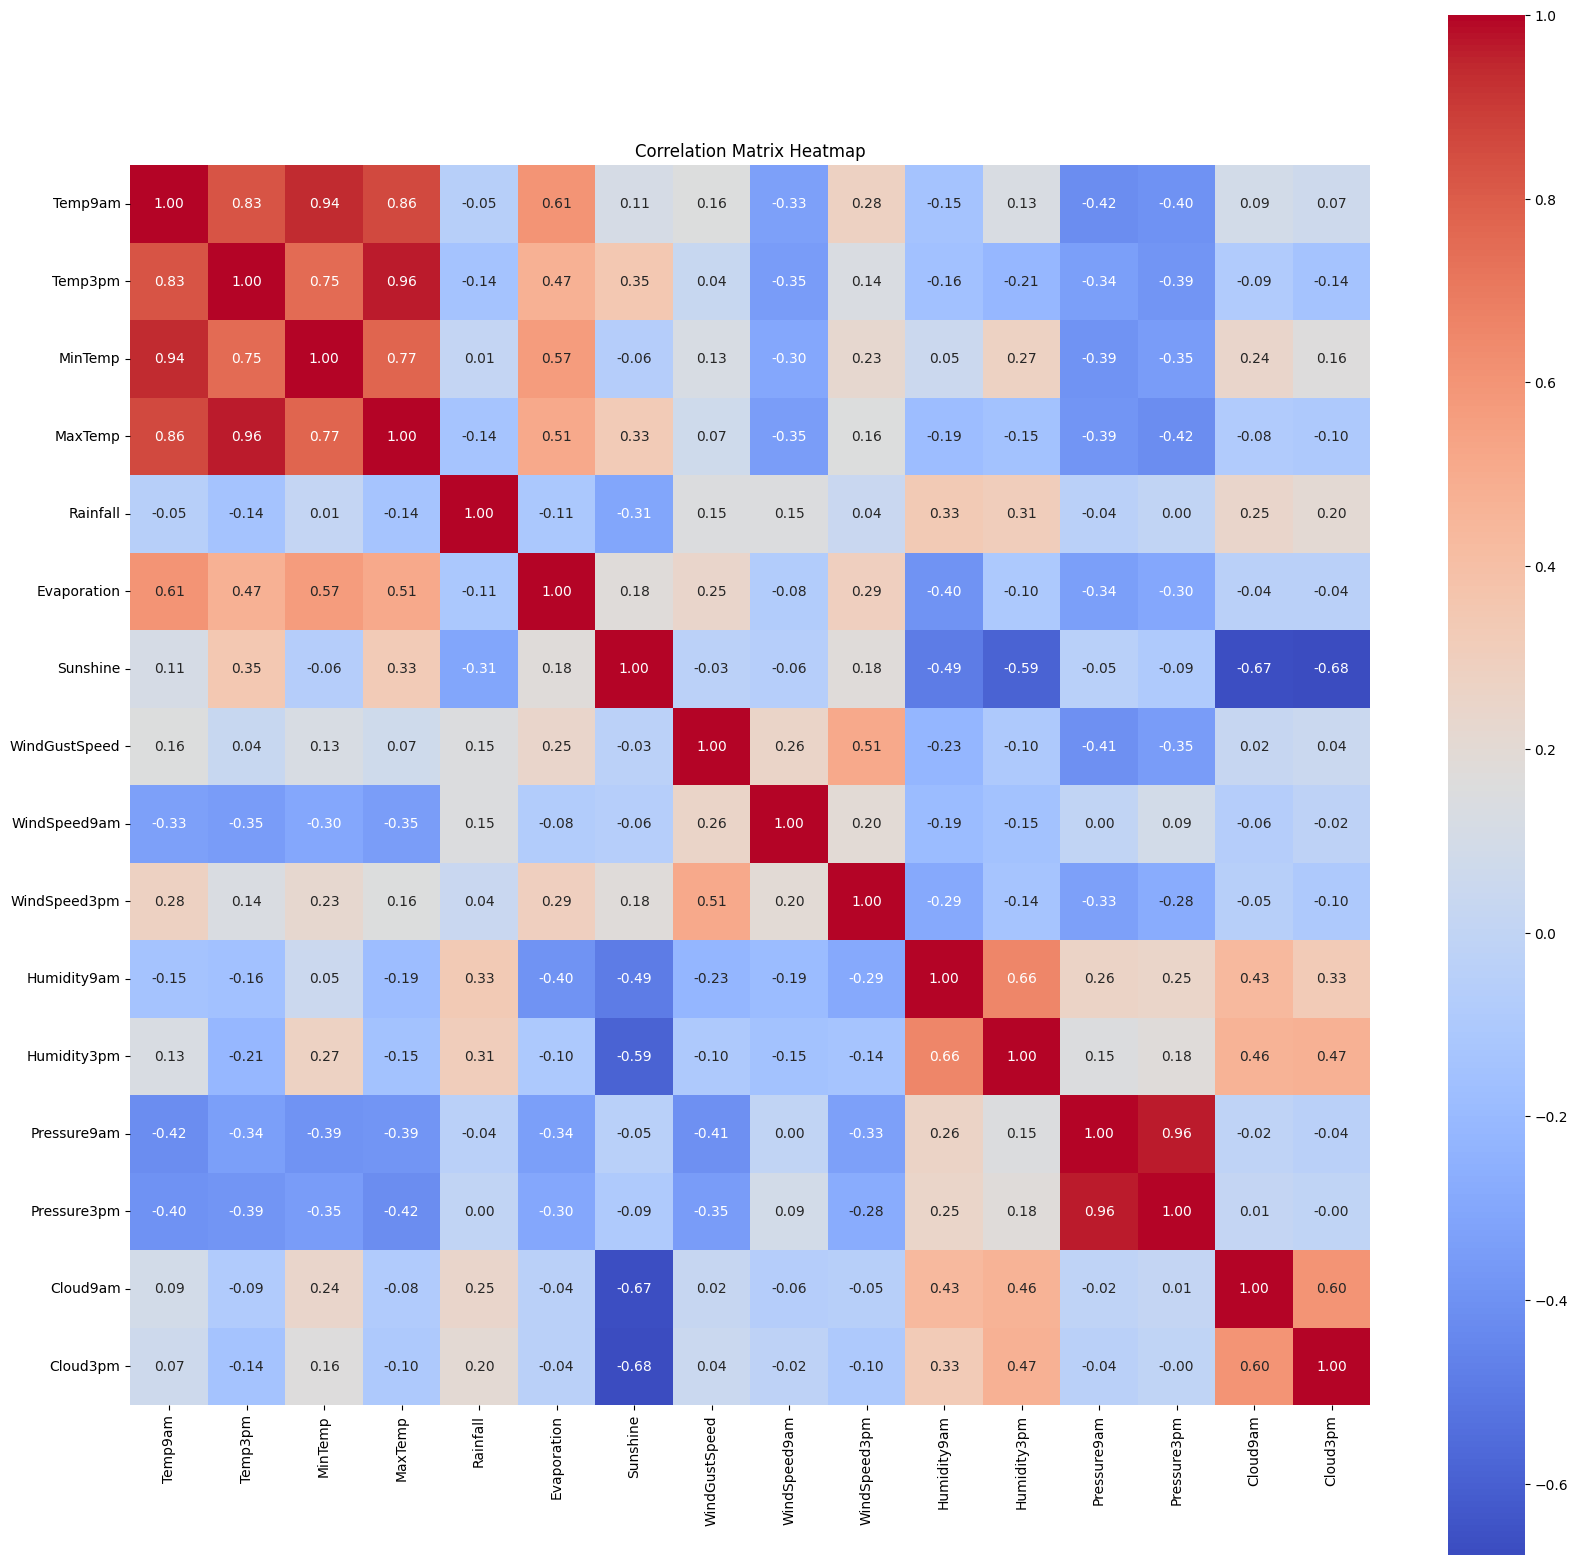

In [92]:
bf = df.select_dtypes(include=[float, int])

numeric_data = bf.dropna()

correlation_matrix = bf.corr()


# Step 6: Plot the correlation matrix heatmap with annotations
plt.figure(figsize=(20, 20))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Matrix Heatmap')
plt.show()

# Data Preprocessing

### Standardize the Variables

In [93]:
from sklearn.preprocessing import StandardScaler

In [94]:
scaler = StandardScaler()

In [95]:
scaler.fit(bf)

StandardScaler()

In [96]:
scaled_features = scaler.transform(bf)

In [97]:
df_feat = pd.DataFrame(scaled_features,columns=bf.columns[:16])
selected_columns = df[['Date','RainToday','WindGustDir', 'WindDir9am', 'WindDir3pm']]
df_feat[['Date','RainToday','WindGustDir', 'WindDir9am', 'WindDir3pm']] = selected_columns.copy()
df_feat.head()

,Temp9am,Temp3pm,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Date,RainToday,WindGustDir,WindDir9am,WindDir3pm
0,0.588229,-0.149813,1.015126,-0.135078,1.236139,0.371460,-1.878965,-0.044081,0.273041,0.094683,...,1.800202,-0.104633,0.199024,1.457110,1.586088,01-02-13,Yes,W,S,SSW
1,0.935624,0.757924,1.015126,0.578719,0.268029,-0.644040,-1.171303,-0.044081,-0.862879,-0.844638,...,1.124391,-0.061892,0.056550,1.061312,1.171306,02-02-13,Yes,W,W,E
2,1.160409,0.338969,1.476258,0.333351,0.328536,-1.006719,-1.852755,-0.044081,0.273041,-2.320714,...,1.923076,-0.232857,-0.057429,1.061312,1.586088,03-02-13,Yes,W,ESE,ESE
3,0.731274,-0.149813,1.168837,-0.045853,1.558843,-1.079254,-1.878965,-0.044081,0.982991,0.094683,...,2.168826,-0.589032,-0.598829,1.457110,1.586088,04-02-13,Yes,W,NNE,E
4,0.956059,0.920852,1.059043,0.601025,7.468346,-0.136290,-1.878965,-0.044081,-0.578899,-1.783959,...,1.185828,-1.429605,-1.596144,1.457110,1.586088,05-02-13,Yes,W,NNE,W


### Transform the Categorical Variables

In [98]:
df_proc = pd.get_dummies(data=df_feat, columns=['WindGustDir', 'WindDir9am', 'WindDir3pm'])
df_proc.head()

,Temp9am,Temp3pm,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,...,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
0,0.588229,-0.149813,1.015126,-0.135078,1.236139,0.371460,-1.878965,-0.044081,0.273041,0.094683,...,False,False,False,False,False,True,False,False,False,False
1,0.935624,0.757924,1.015126,0.578719,0.268029,-0.644040,-1.171303,-0.044081,-0.862879,-0.844638,...,False,False,False,False,False,False,False,False,False,False
2,1.160409,0.338969,1.476258,0.333351,0.328536,-1.006719,-1.852755,-0.044081,0.273041,-2.320714,...,False,False,False,False,False,False,False,False,False,False
3,0.731274,-0.149813,1.168837,-0.045853,1.558843,-1.079254,-1.878965,-0.044081,0.982991,0.094683,...,False,False,False,False,False,False,False,False,False,False
4,0.956059,0.920852,1.059043,0.601025,7.468346,-0.136290,-1.878965,-0.044081,-0.578899,-1.783959,...,False,False,False,False,False,False,False,True,False,False


In [99]:
df_proc.replace(['No', 'Yes'], [0,1], inplace=True)
df_proc[['Date','RainToday']]

,Date,RainToday
0,01-02-13,1
1,02-02-13,1
2,03-02-13,1
3,04-02-13,1
4,05-02-13,1
...,...,...
3266,11-01-22,0
3267,12-01-22,0
3268,13-01-22,0
3269,14-01-22,0


In [100]:
df_proc.drop('Date',axis=1,inplace=True)

# Spliting Dataset into Training and Test Set

In [101]:
df_proc = df_proc.astype(float)

In [102]:
features = df_proc.drop(columns='RainToday', axis=1)
Y = df_proc['RainToday']

In [103]:
x_train, x_test, y_train, y_test = train_test_split(features, Y, test_size=0.35, random_state=101)

# Raifall Occurance (Yes or No) Predicting Algorithms

## Logistic Regression Model

In [104]:
LR = LogisticRegression()
LR.fit(x_train,y_train)

LogisticRegression()

## KNN Classification Model

In [105]:
KNN = KNeighborsClassifier(n_neighbors=4)
KNN.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=4)

## Decision Tree Classification Model

In [106]:
Tree = DecisionTreeClassifier()
Tree.fit(x_train,y_train)

DecisionTreeClassifier()

## SVM Classification Model

In [107]:
SVM = svm.SVC(kernel='linear')
SVM.fit(x_train, y_train)

SVC(kernel='linear')

## Random Forest Classification Model

In [108]:
RFC = RandomForestClassifier(n_estimators=100)
RFC.fit(x_train, y_train)

RandomForestClassifier()

# Rainfall Occurance Prediction Report

In [109]:
LR_Accuracy_Score = metrics.accuracy_score(LR.predict(x_test), y_test)
KNN_Accuracy_Score = metrics.accuracy_score(KNN.predict(x_test), y_test)
Tree_Accuracy_Score = metrics.accuracy_score(Tree.predict(x_test), y_test)
SVM_Accuracy_Score = metrics.accuracy_score(SVM.predict(x_test), y_test)
RFC_Accuracy_Score = metrics.accuracy_score(RFC.predict(x_test), y_test)

LR_F1_Score = metrics.f1_score(LR.predict(x_test), y_test, average='weighted')
KNN_F1_Score = metrics.f1_score(KNN.predict(x_test), y_test, average='weighted')
Tree_F1_Score = metrics.f1_score(Tree.predict(x_test), y_test, average='weighted')
SVM_F1_Score = metrics.f1_score(SVM.predict(x_test), y_test, average='weighted')
RFC_F1_Score = metrics.f1_score(RFC.predict(x_test), y_test, average='weighted')

Report = {
    'Classification Algorithm': ['Logistic Regression', 'KNN', 'Decision Tree', 'SVM', 'Random Forest'],
    'Accuracy Score': [LR_Accuracy_Score, KNN_Accuracy_Score, Tree_Accuracy_Score, SVM_Accuracy_Score, RFC_Accuracy_Score],
    'F1-score': [LR_F1_Score, KNN_F1_Score, Tree_F1_Score, SVM_F1_Score, RFC_F1_Score]
}
Report = pd.DataFrame(Report)

print(Report)

  Classification Algorithm  Accuracy Score  F1-score
0      Logistic Regression        0.823581  0.831675
1                      KNN        0.800000  0.825270
2            Decision Tree        0.769432  0.768469
3                      SVM        0.828821  0.839233
4            Random Forest        0.828821  0.841084


In [110]:
import plotly.express as px

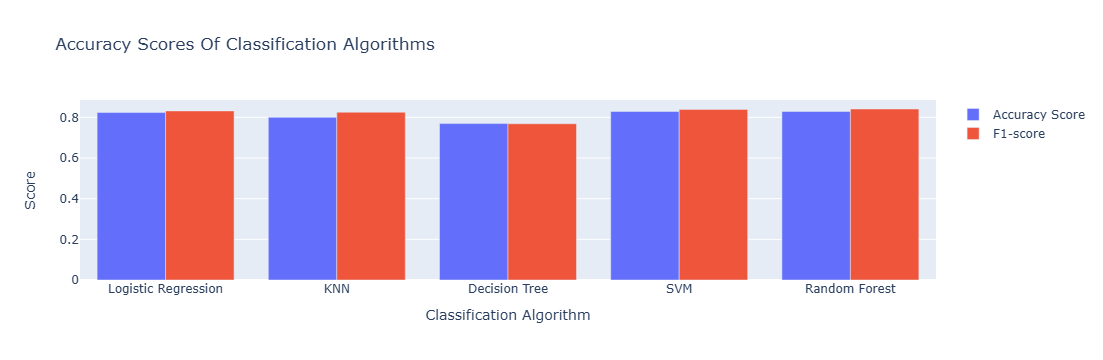

In [111]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(rows=1, cols=1)

fig.add_trace(
    go.Bar(x=Report['Classification Algorithm'], y=Report['Accuracy Score'], name='Accuracy Score'),
    row=1, col=1
)

fig.add_trace(
    go.Bar(x=Report['Classification Algorithm'], y=Report['F1-score'], name='F1-score'), row=1,col=1
)
fig.update_layout(title_text="Accuracy Scores Of Classification Algorithms")
fig.update_yaxes(title_text="Score", row=1, col=1)
fig.update_xaxes(title_text="Classification Algorithm", row=1, col=1)
fig.show()

# Rainfall Ammount Prediction Algorithms

### Splitting the Dataset

In [112]:
df_proc = df_proc.astype(float)

In [113]:
features = df_proc.drop(columns='Rainfall', axis=1)
Y = df_proc['Rainfall']

In [114]:
x_train, x_test, y_train, y_test = train_test_split(features, Y, test_size=0.35, random_state=101)

### Linear Regression

In [115]:
LinearReg = LinearRegression()
LinearReg.fit(x_train, y_train)

LinearRegression()

### Random Forest Regression Model

In [116]:
RFR = RandomForestRegressor()
RFR.fit(x_train, y_train)

RandomForestRegressor()

### SVM REgression Model

In [117]:
SVRR = SVR()
SVRR.fit(x_train, y_train)

SVR()

# Rainfall Amount Prediction Report

In [118]:
LinearRegression_MAE = metrics.mean_absolute_error(LinearReg.predict(x_test), y_test)
LinearRegression_MSE = metrics.mean_squared_error(LinearReg.predict(x_test), y_test, squared=False)

RandomForest_MAE = metrics.mean_absolute_error(RFR.predict(x_test), y_test)
RandomForest_MSE = metrics.mean_squared_error(RFR.predict(x_test), y_test, squared=False)

SVM_MAE = metrics.mean_absolute_error(SVRR.predict(x_test), y_test)
SVM_MSE = metrics.mean_squared_error(SVRR.predict(x_test), y_test, squared=False)


Report = {'Regression Algorithm': ['Linear Regression','Random Forest', 'SVM'],
          'MAE': [LinearRegression_MAE,RandomForest_MAE, SVM_MAE],
          'RMSE': [LinearRegression_MSE,RandomForest_MSE, SVM_MSE],}
Report = pd.DataFrame(Report)
Report

,Regression Algorithm,MAE,RMSE
0,Linear Regression,0.498764,0.948275
1,Random Forest,0.383357,0.898847
2,SVM,0.365070,0.971967


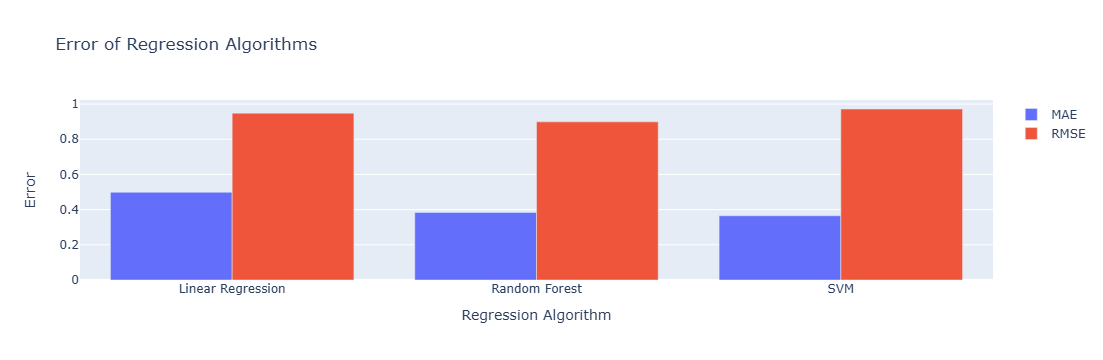

In [119]:
fig = make_subplots(rows=1, cols=1)

fig.add_trace(
    go.Bar(x=Report['Regression Algorithm'], y=Report['MAE'], name='MAE'),
    row=1, col=1
)

fig.add_trace(
    go.Bar(x=Report['Regression Algorithm'], y=Report['RMSE'], name='RMSE'), row=1,col=1
)
fig.update_layout(title_text="Error of Regression Algorithms")
fig.update_yaxes(title_text="Error", row=1, col=1)
fig.update_xaxes(title_text="Regression Algorithm", row=1, col=1)
fig.show()